# 02 — Feature engineering and candidate road preparation

This notebook shows the actual source-code path used in both training and inference: Trip.load → RoadIndex → candidate_ids → features → make_rows. The demonstration uses **training trip 00000001**. Six candidate arcs are prepared per sampled GPS observation. The reference route is used only to construct proxy training/evaluation labels, not inference features.

In [1]:
import os
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from matplotlib.collections import LineCollection
from pathsnap import Trip, RoadIndex, make_rows, FEATURE_NAMES

DATA_ROOT = Path(os.environ.get("PATHSNAP_DATA_ROOT","data"))
trip = Trip.load(DATA_ROOT/"train"/"00000001",include_route=True)
road, ids, candidates, features, labels = make_rows(trip,max_points=120,candidate_count=6)
print("GPS observations sampled:",len(ids),"candidate arcs per point:",candidates.shape[1])
print("Model feature tensor:",features.shape,"candidate rows:",features.shape[0]*features.shape[1])
print("Proxy reference candidate coverage:",round(100*labels.any(axis=1).mean(),2),"%")

GPS observations sampled: 120 candidate arcs per point: 6
Model feature tensor: (120, 6, 6) candidate rows: 720
Proxy reference candidate coverage: 89.17 %


## Six features: physical meaning and reason

| Feature | Meaning | Why it helps |
|---|---|---|
| log1p_distance_m | GPS point to candidate road segment | Nearby roads are more plausible |
| direction_cos | Agreement between GPS movement and directed road arc | Distinguishes parallel/reverse roads |
| log1p_speed_mps | Movement per elapsed second | Interprets plausible motion and GPS jumps |
| log1p_segment_length_m | Length of candidate arc | Captures road geometry scale |
| log1p_time_gap_s | Time since previous GPS observation | Larger gaps permit farther travel |
| log1p_movement_m | Straight-line movement since prior observation | Gives context to direction and speed |

The code projects longitude/latitude locally to approximate metres, uses a KD-tree on arc endpoints/midpoints for fast candidate proposals, then ranks candidates by exact point-to-segment distance. log1p compresses large nonnegative values; direction cosine remains in [-1,1]. Speed, movement, and time gap are related but tree boosting can learn their interactions.

In [2]:
frame = pd.DataFrame(features.reshape(-1,6),columns=FEATURE_NAMES)
frame["gps_index"] = np.repeat(ids,6)
frame["candidate_arc_id"] = candidates.ravel()
frame["proxy_positive_label"] = labels.ravel()
for field in ("distance_m","speed_mps","segment_length_m","time_gap_s","movement_m"):
    frame[field] = np.expm1(frame["log1p_"+field])
display(frame[["gps_index","candidate_arc_id","distance_m","direction_cos","speed_mps",
               "segment_length_m","time_gap_s","movement_m","proxy_positive_label"]].head(12))
display(frame.groupby("proxy_positive_label")[["distance_m","direction_cos","segment_length_m"]].median().round(2))

,gps_index,candidate_arc_id,distance_m,direction_cos,speed_mps,segment_length_m,time_gap_s,movement_m,proxy_positive_label
0,0,64973,0.718268,0.000000,0.000000,293.562897,0.0,0.000000,1
1,0,117639,15.028051,0.000000,0.000000,1021.566326,0.0,0.000000,0
2,0,2641,32.235425,0.000000,0.000000,425.522987,0.0,0.000000,0
3,0,53932,92.396244,0.000000,0.000000,169.246555,0.0,0.000000,0
4,0,50652,92.396244,0.000000,0.000000,169.246555,0.0,0.000000,0
5,0,50585,96.016109,0.000000,0.000000,223.690368,0.0,0.000000,0
6,11,8970,2.174293,0.999799,57.626083,169.029834,1.0,57.626083,1
7,11,117639,12.854732,-0.999795,57.626083,1021.566326,1.0,57.626083,0
8,11,117640,25.119246,-0.999627,57.626083,228.309526,1.0,57.626083,0
9,11,133950,61.713724,0.999781,57.626083,27.607447,1.0,57.626083,0


,distance_m,direction_cos,segment_length_m
proxy_positive_label,,,
0,22.99,-0.13,66.55
1,4.18,0.99,104.79


## Actual feature distributions

These plots use the 120 sampled observations × six candidate arcs from training trip 00000001. Orange denotes the proxy reference candidate and blue the other candidates. Distributions overlap, which is why the model combines several features instead of using only distance.

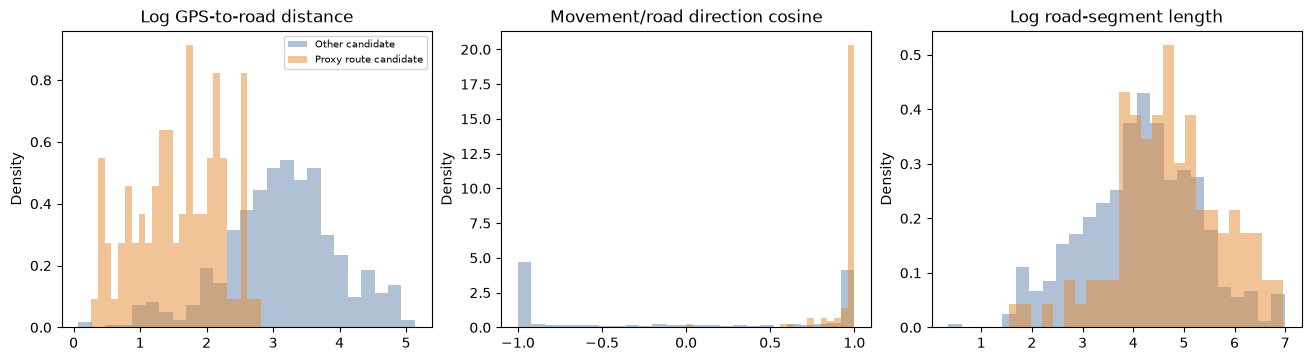

In [3]:
fig,axes=plt.subplots(1,3,figsize=(13,3.5),layout="constrained")
for label,color,name in ((0,"#6385ad","Other candidate"),(1,"#e58b33","Proxy route candidate")):
    s=frame[frame.proxy_positive_label==label]
    axes[0].hist(s["log1p_distance_m"],bins=25,density=True,alpha=.5,color=color,label=name)
    axes[1].hist(s["direction_cos"],bins=25,density=True,alpha=.5,color=color,label=name)
    axes[2].hist(s["log1p_segment_length_m"],bins=25,density=True,alpha=.5,color=color,label=name)
for ax,title in zip(axes,["Log GPS-to-road distance","Movement/road direction cosine","Log road-segment length"]):
    ax.set_title(title);ax.set_ylabel("Density")
axes[0].legend(fontsize=7)
plt.show()

## Candidate geometry and proxy-label limit

The grey lines are six nearby candidate arcs for the first few GPS points; orange is the reference-route arc geometry, and blue points are recorded GPS samples. Candidate generation can miss the correct arc. The .route file does not give one label per GPS point, so labels are made by finding each point's nearest reference-route arc; this is a heuristic, not verified ground truth.

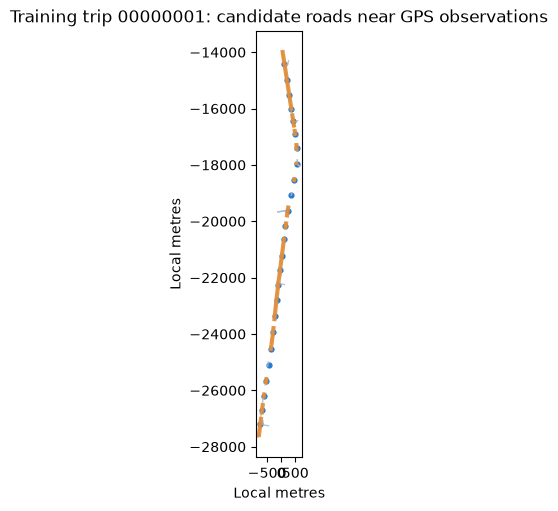

In [4]:
sample_ids=np.arange(min(25,len(ids)))
arc_ids=np.unique(candidates[sample_ids].ravel())
fig,ax=plt.subplots(figsize=(9,5),layout="constrained")
ax.add_collection(LineCollection(np.stack((road.a[arc_ids],road.b[arc_ids]),axis=1),colors="#aab7c6",linewidths=1,alpha=.8))
ref=np.unique(trip.route)
visible=np.intersect1d(arc_ids,ref)
if len(visible): ax.add_collection(LineCollection(np.stack((road.a[visible],road.b[visible]),axis=1),colors="#e58b33",linewidths=3,alpha=.9))
ax.scatter(road.track_xy[ids[sample_ids],0],road.track_xy[ids[sample_ids],1],s=12,color="#2779d1")
ax.autoscale();ax.set_aspect("equal",adjustable="box")
ax.set(title="Training trip 00000001: candidate roads near GPS observations",xlabel="Local metres",ylabel="Local metres")
plt.show()

## Source-code links for evaluators

The complete implementation is in pathsnap.py: Trip.load reads and cleans the track; RoadIndex.candidate_ids proposes and ranks directed arcs; RoadIndex.features computes six numbers; make_rows constructs the feature matrix and proxy labels. feature_example.py exports real physical-value examples to artifacts/feature_sample.csv. The same make_rows function is used by train.py and server.py, preventing training/inference feature mismatch.